Name - Shreyashi Hemant Bandey

Batch - B3(B2)

ROll no. - 64

Min-Max Normalization

In [ ]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler

data = np.array([[10000],[25000],[50000],[75000],[100000]])

scaler = MinMaxScaler()
normalized = scaler.fit_transform(data)

print(normalized)


[[0.        ]
 [0.16666667]
 [0.44444444]
 [0.72222222]
 [1.        ]]


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
standardized = scaler.fit_transform(data)

print(standardized)

[[-1.28638417]
 [-0.82696125]
 [-0.06125639]
 [ 0.70444848]
 [ 1.47015334]]


Label Encoding

In [ ]:

data = [2,4,6,8,2,4,6]
from sklearn.preprocessing import LabelEncoder
Le = LabelEncoder()
Edata = Le.fit_transform(data)
print(Edata)

[0 1 2 3 0 1 2]


In [ ]:

from sklearn.preprocessing import OneHotEncoder
import numpy as np
data = [['Red'],['Blue'],['Green']]
print(data)
ohe = OneHotEncoder()
Edata = ohe.fit_transform(data)
print(Edata.toarray())

[['Red'], ['Blue'], ['Green']]
[[0. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]]


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression,Lasso,Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [ ]:
data = {
    'Hours': [
        1,2,3,4,5,
        6,7,8,9,10,
        11,12,13,14,15,
        16,17,18,19,20
    ],

    'Score': [
        35,40,45,50,55,
        60,62,65,68,70,
        72,75,78,80,82,
        85,87,90,92,95
    ]
}

In [ ]:
df = pd.DataFrame(data)
print(df)


    Hours  Score
0       1     35
1       2     40
2       3     45
3       4     50
4       5     55
5       6     60
6       7     62
7       8     65
8       9     68
9      10     70
10     11     72
11     12     75
12     13     78
13     14     80
14     15     82
15     16     85
16     17     87
17     18     90
18     19     92
19     20     95


In [ ]:
print("DATASET INFORMATION")

print("Number of Observations :", len(df))
print("Number of variables: ", len(df.columns))
print("Statistical Summary")
print(df.describe())

DATASET INFORMATION
Number of Observations : 20
Number of variables:  2
Statistical Summary
          Hours      Score
count  20.00000  20.000000
mean   10.50000  69.300000
std     5.91608  17.648915
min     1.00000  35.000000
25%     5.75000  58.750000
50%    10.50000  71.000000
75%    15.25000  82.750000
max    20.00000  95.000000


In [ ]:
#Independent Var
X = df[['Hours']]

# Dependent
Y = df['Score']

print("Independent Variables (X): Hours Studied")
print
print("Dependent Variables (Y) : Exam Score")
print(Y)

Independent Variables (X): Hours Studied
Dependent Variables (Y) : Exam Score
0     35
1     40
2     45
3     50
4     55
5     60
6     62
7     65
8     68
9     70
10    72
11    75
12    78
13    80
14    82
15    85
16    87
17    90
18    92
19    95
Name: Score, dtype: int64


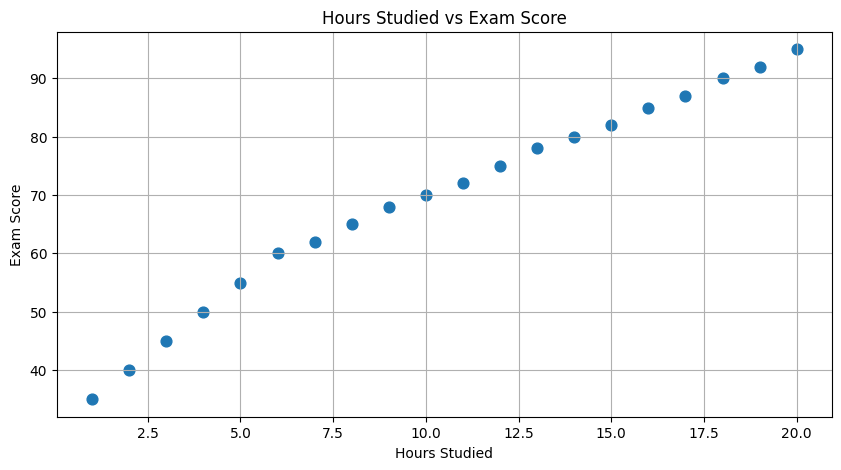

In [ ]:
plt.figure(figsize=(10,5))
plt.scatter(X,Y,s=60)
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.title("Hours Studied vs Exam Score")
plt.grid(True)
plt.show()

In [ ]:
X_Train, X_Test, Y_Train, Y_Test = train_test_split(X,Y, test_size=0.20, random_state=42)
print("Traing Sample : ", len(X_Train))
print("Testing Sample : ", len(X_Test))

Traing Sample :  16
Testing Sample :  4


In [ ]:
scaler = StandardScaler()
X_Train = scaler.fit_transform(X_Train)
X_Test = scaler.transform(X_Test)

In [ ]:
# Simple Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_Train, Y_Train)
linear_pred = linear_model.predict(X_Test)
print("Intercept : ",linear_model.intercept_)
print("Slope : ",linear_model.coef_[0])
print("Regression Equation : ")
print("Score = ",round(linear_model.intercept_,2),"+",round(linear_model.coef_[0],2),"x Hours")

Intercept :  71.0
Slope :  13.950469290487069
Regression Equation : 
Score =  71.0 + 13.95 x Hours


In [ ]:
#Ridge Regression
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_Train, Y_Train)
ridge_pred = ridge_model.predict(X_Test)
print("Ridge Regression")
print("=" * 50)
print("Alpha: ", ridge_model.alpha)
print("Intercept: ",round(ridge_model.intercept_,2))
print("Coefficients: ",round(ridge_model.coef_[0],2))

Ridge Regression
Alpha:  1.0
Intercept:  71.0
Coefficients:  13.13


In [ ]:
#Laso regression
lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_Train, Y_Train)
lasso_pred = lasso_model.predict(X_Test)
print("Lasso Regression")
print("=" * 50)
print("Alpha: ", lasso_model.alpha)
print("Intercept: ",round(lasso_model.intercept_,2))
print("Coefficients: ",round(lasso_model.coef_[0],2))

Lasso Regression
Alpha:  0.1
Intercept:  71.0
Coefficients:  13.85


In [ ]:
#Decision Tree Regression
tree_model = DecisionTreeRegressor(random_state=42,max_depth=3)
tree_model.fit(X_Train, Y_Train)
tree_pred = tree_model.predict(X_Test)
print("Decision Tree Regression")
print("=" * 50)
print("Maximum Depth: ", tree_model.max_depth)

Decision Tree Regression
Maximum Depth:  3


In [ ]:
# Random Forest regression
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42,max_depth=3)
rf_model.fit(X_Train, Y_Train)
rf_pred = rf_model.predict(X_Test)
print("Random Forest Regression")
print("=" * 50)
print("Number of Estimators: ", rf_model.n_estimators)
print("Maximum Depth: ", rf_model.max_depth)

Random Forest Regression
Number of Estimators:  100
Maximum Depth:  3


In [ ]:
prediction ={
    'Linear Regression' : linear_pred,
    'Ridge Regression' : ridge_pred,
    'Lasso Regression' : lasso_pred,
    'Decision Tree Regression' : tree_pred,
    'Random Forest Regression' : rf_pred
}


In [ ]:
results = []
for model_name, pred in prediction.items():
    mae = mean_absolute_error(Y_Test, pred)
    mse = mean_squared_error(Y_Test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(Y_Test, pred)
    results.append({
        'Model': model_name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2': r2
    })

In [ ]:
metrics_df = pd.DataFrame(results)
print(metrics_df)

                      Model       MAE        MSE      RMSE        R2
0         Linear Regression  4.217086  32.563883  5.706477  0.948414
1          Ridge Regression  5.006352  45.771060  6.765431  0.927491
2          Lasso Regression  4.247787  33.997678  5.830753  0.946142
3  Decision Tree Regression  5.875000  40.562500  6.368870  0.935743
4  Random Forest Regression  5.988250  57.626970  7.591243  0.908710


In [ ]:
comparision = pd.DataFrame({
    'Hours' : df.loc[Y_Test.index, 'Hours'].values,
    'Actual Score' : Y_Test.values,
    'Linear Regression' : linear_pred,
    'Ridge Regression' : ridge_pred,
    'Lasso Regression' : lasso_pred,
    'Decision Tree Regression' : tree_pred,
    'Random Forest Regression' : rf_pred
})
comparision = comparision.sort_values(by='Hours')
print(comparision)
print(comparision.round(2).to_string(index=False))

   Hours  Actual Score  Linear Regression  Ridge Regression  Lasso Regression  \
0      1            35          44.103303         45.685461         44.296104   
3      2            40          46.844367         48.265287         47.017520   
2     16            85          85.219273         84.382845         85.117346   
1     18            90          90.701403         89.542496         90.560179   

   Decision Tree Regression  Random Forest Regression  
0                      45.0                 47.774333  
3                      45.0                 47.774333  
2                      80.0                 82.559833  
1                      93.5                 90.964167  
 Hours  Actual Score  Linear Regression  Ridge Regression  Lasso Regression  Decision Tree Regression  Random Forest Regression
     1            35              44.10             45.69             44.30                      45.0                     47.77
     2            40              46.84             48.27 

Plot Bar Plot

/tmp/ipykernel_722/1084202508.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='R2', data=metrics_df, palette='viridis')


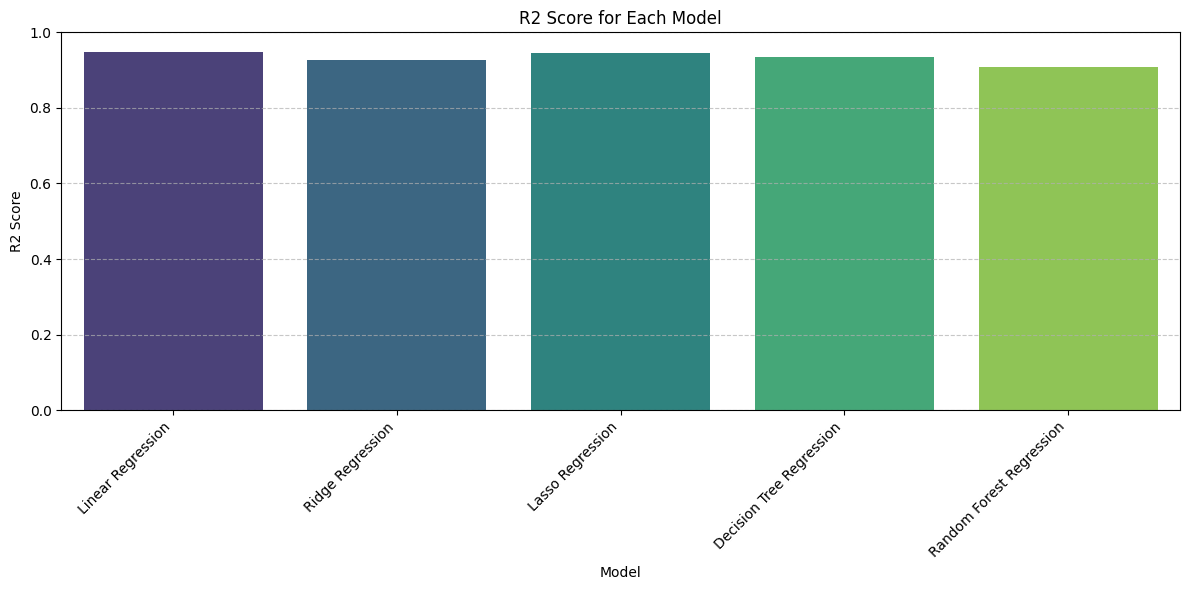

In [ ]:
plt.figure(figsize=(12, 6))
sns.barplot(x='Model', y='R2', data=metrics_df, palette='viridis')
plt.title('R2 Score for Each Model')
plt.xlabel('Model')
plt.ylabel('R2 Score')
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 1) # R2 score is between 0 and 1
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

/tmp/ipykernel_722/2831707694.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='RMSE', data=metrics_df, palette='magma')


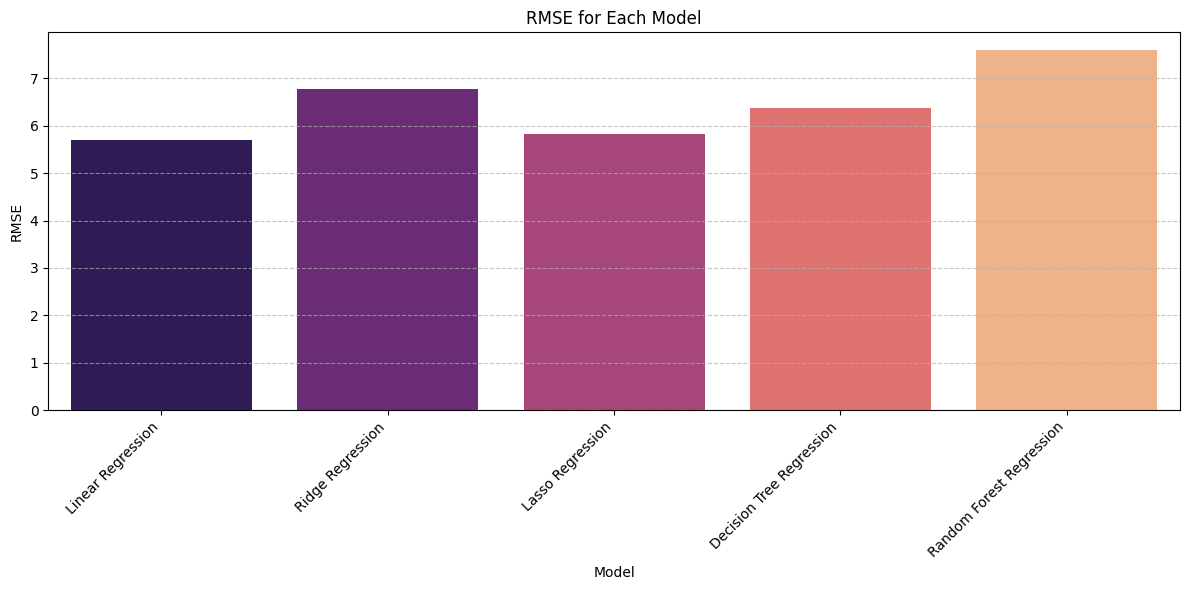

In [ ]:
plt.figure(figsize=(12, 6))
sns.barplot(x='Model', y='RMSE', data=metrics_df, palette='magma')
plt.title('RMSE for Each Model')
plt.xlabel('Model')
plt.ylabel('RMSE')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
X_range = np.linspace(X['Hours'].min(), X['Hours'].max(), 100).reshape(-1, 1)
X_range

array([[ 1.        ],
       [ 1.19191919],
       [ 1.38383838],
       [ 1.57575758],
       [ 1.76767677],
       [ 1.95959596],
       [ 2.15151515],
       [ 2.34343434],
       [ 2.53535354],
       [ 2.72727273],
       [ 2.91919192],
       [ 3.11111111],
       [ 3.3030303 ],
       [ 3.49494949],
       [ 3.68686869],
       [ 3.87878788],
       [ 4.07070707],
       [ 4.26262626],
       [ 4.45454545],
       [ 4.64646465],
       [ 4.83838384],
       [ 5.03030303],
       [ 5.22222222],
       [ 5.41414141],
       [ 5.60606061],
       [ 5.7979798 ],
       [ 5.98989899],
       [ 6.18181818],
       [ 6.37373737],
       [ 6.56565657],
       [ 6.75757576],
       [ 6.94949495],
       [ 7.14141414],
       [ 7.33333333],
       [ 7.52525253],
       [ 7.71717172],
       [ 7.90909091],
       [ 8.1010101 ],
       [ 8.29292929],
       [ 8.48484848],
       [ 8.67676768],
       [ 8.86868687],
       [ 9.06060606],
       [ 9.25252525],
       [ 9.44444444],
       [ 9

In [ ]:
x = np.linspace(1,10,200)
x

array([ 1.        ,  1.04522613,  1.09045226,  1.13567839,  1.18090452,
        1.22613065,  1.27135678,  1.31658291,  1.36180905,  1.40703518,
        1.45226131,  1.49748744,  1.54271357,  1.5879397 ,  1.63316583,
        1.67839196,  1.72361809,  1.76884422,  1.81407035,  1.85929648,
        1.90452261,  1.94974874,  1.99497487,  2.04020101,  2.08542714,
        2.13065327,  2.1758794 ,  2.22110553,  2.26633166,  2.31155779,
        2.35678392,  2.40201005,  2.44723618,  2.49246231,  2.53768844,
        2.58291457,  2.6281407 ,  2.67336683,  2.71859296,  2.7638191 ,
        2.80904523,  2.85427136,  2.89949749,  2.94472362,  2.98994975,
        3.03517588,  3.08040201,  3.12562814,  3.17085427,  3.2160804 ,
        3.26130653,  3.30653266,  3.35175879,  3.39698492,  3.44221106,
        3.48743719,  3.53266332,  3.57788945,  3.62311558,  3.66834171,
        3.71356784,  3.75879397,  3.8040201 ,  3.84924623,  3.89447236,
        3.93969849,  3.98492462,  4.03015075,  4.07537688,  4.12

In [ ]:
linear_curve = linear_model.predict(scaler.transform(pd.DataFrame(X_range, columns=['Hours'])))
ridge_curve = ridge_model.predict(scaler.transform(pd.DataFrame(X_range, columns=['Hours'])))
lasso_curve = lasso_model.predict(scaler.transform(pd.DataFrame(X_range, columns=['Hours'])))
tree_curve = tree_model.predict(scaler.transform(pd.DataFrame(X_range, columns=['Hours'])))
rf_curve = rf_model.predict(scaler.transform(pd.DataFrame(X_range, columns=['Hours'])))

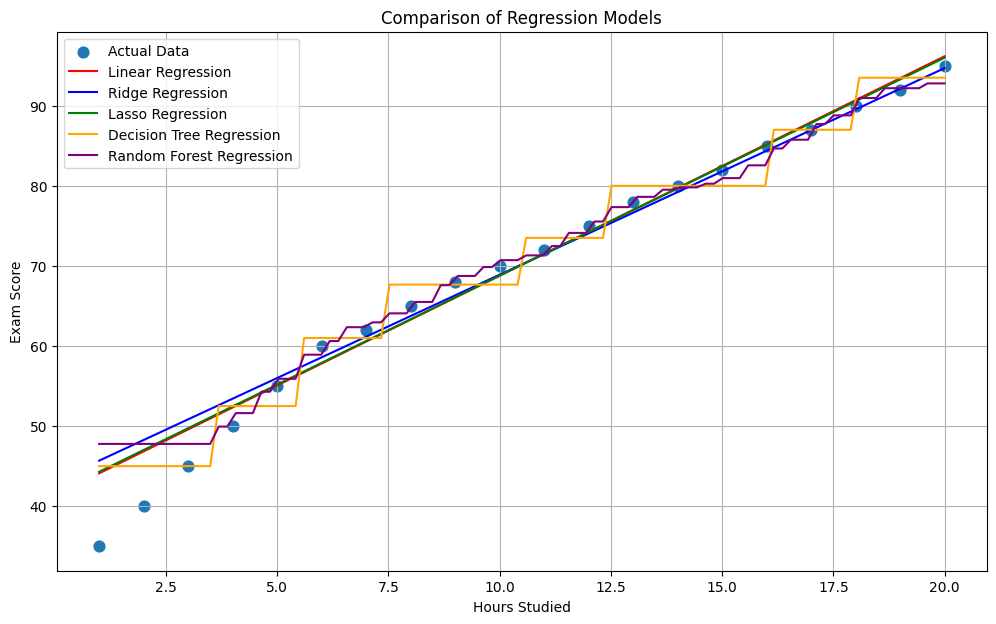

In [ ]:
#Plot all regression models
plt.figure(figsize=(12,7))
plt.scatter(X,Y,s=60,label='Actual Data')
plt.plot(X_range,linear_curve,color='red',label='Linear Regression')
plt.plot(X_range,ridge_curve,color='blue',label='Ridge Regression')
plt.plot(X_range,lasso_curve,color='green',label='Lasso Regression')
plt.plot(X_range,tree_curve,color='orange',label='Decision Tree Regression')
plt.plot(X_range,rf_curve,color='purple',label='Random Forest Regression')
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')
plt.title('Comparison of Regression Models')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
new_hours = [[12]]
new_linear = linear_model.predict(new_hours)[0]
new_ridge = ridge_model.predict(scaler.transform(new_hours))[0]
new_lasso = lasso_model.predict(scaler.transform(new_hours))[0]
new_tree = tree_model.predict(new_hours)[0]
new_rf = rf_model.predict(new_hours)[0]
prediction_result = pd.DataFrame({
    'MODEL': ['Linear Regression', 'Ridge Regression', 'Lasso Regression', 'Decision Tree Regression', 'Random Forest Regression'],
    'PREDICTED SCORE': [new_linear, new_ridge, new_lasso, new_tree, new_rf]
})
print("Prediction for New Student")
print("Hours Studied :", new_hours[0][0])
print(prediction_result.round(2).to_string(index=False))


Prediction for New Student
Hours Studied : 12
                   MODEL  PREDICTED SCORE
       Linear Regression           238.41
        Ridge Regression            74.06
        Lasso Regression            74.23
Decision Tree Regression            93.50
Random Forest Regression            92.79


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [ ]:
models = {
    "Linear Regression": linear_model,
    "Ridge Regression": ridge_model,
    "Lasso Regression": lasso_model,
    "Decision Tree Regression": tree_model,
    "Random Forest Regression": rf_model
}

In [ ]:
best_model_name = metrics_df.loc[metrics_df['R2'].idxmax(), 'Model']
best_model = models[best_model_name]
print("Best Model: ", best_model_name)

Best Model:  Linear Regression


PICKLE FILE

In [ ]:
import joblib

joblib.dump(best_model, 'best_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

['scaler.pkl']

In [ ]:
model = joblib.load('best_model.pkl')
scaler = joblib.load('scaler.pkl')

In [ ]:
def predict_score(hours):
  sample_hours = np.array([hours])
  #sample_hours_scaled = scaler.transform(sample_hours)      (this is only used in laso and riedge not in linear regression)
  predicted = model.predict([sample_hours])
  return f"Predicted Score Based on Hours : {int(predicted[0])}"

In [ ]:
import gradio as gr

interface = gr.Interface(
    fn=predict_score,
    inputs=[gr.Number(label='Enter Hours')],
    outputs="text",
    title="Score prediction system based on hours" ,
    description="Enter Hour"
)

interface.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e8e14c41480684e82a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
